# Lab 08 — Deep learning II: an LSTM for time series

*Forecast the next hour of electricity demand for 158 customers from the previous twenty-four*

**Goal.** Add up four years of meter readings into one demand series, split it by date, turn it into supervised windows, set three free forecasts any model must beat, train an LSTM that keeps its best epoch, open the test half-year once, find the hours it gets most wrong, and save the weights with the scaling they depend on.

**Data.** `all_datasets/advanced/electricity_load/electricity_load_hourly.zip`: hourly electricity use of 158 Portuguese customers, 2011 to 2014 (Trindade, 2015)

**Reading.** Chapter 30: sequence models, windows and naive baselines; early stopping in Chapter 28; the time-split rule in Chapter 4.

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab08_deep_learning_lstm/lab08_deep_learning_lstm_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab08_deep_learning_lstm/lab08_deep_learning_lstm_worked.py`.

**Evidence.** `results/lab08/` — demand plots, the validation curve against three free forecasts, test metrics, the first test week and the error by hour; `models/electricity_lstm.pt` and its card

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Build one demand series, split it by date, cut it into windows | 2–4 |
| B | Score three free forecasts | 5 |
| C | Train the LSTM, test it once, find the hours it gets wrong | 6–9 |
| D | Save the weights and the scale, then forecast the first hour of 2015 | 10 |
| Finish | Save the evidence; then try other lookbacks and a wider LSTM | 11–13 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab08/`, and the weights to `models/`.

**PyTorch and the device.** As in Lab 7, `start_pytorch()` imports PyTorch, installing the CPU build once if it is missing, and picks `DEVICE`: an NVIDIA GPU (`cuda`) or Apple GPU (`mps`) when PyTorch can see one, otherwise the CPU. The numbers on the lab sheet come from a CPU run; a GPU run differs in the last digits.

### Question 1 — Setup

**Read the code.**

- The setup is Lab 7's. `copy` is new: it makes an independent copy of a model's weights, which the training loop uses to remember its best epoch.

**Read the code.**

- The setup is Lab 7's. `copy` is new: it makes an independent copy of a model's weights, which the training loop uses to remember its best epoch.

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab, start_pytorch

# 2. PyTorch: installed once if missing; then the device to train on
#    (a GPU if PyTorch can see one, else the CPU).
DEVICE = start_pytorch()
import torch
from torch import nn

# 3. The other libraries this lab uses.
import copy                                  # to keep a copy of the best weights while training
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 4. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab08")

Python 3.13.9 at C:\ProgramData\anaconda3\python.exe
PyTorch 2.11.0+cu128 | device: cpu


course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab08/ and models/


## Part A — From meter readings to windows

**Goal.** Add up the customers into one demand series, split it by date, and turn it into supervised windows.

*Questions 2–4 · Data: hourly electricity use of 158 customers*

### Question 2 — Read the meters and add them up

The file holds one column per customer: kWh used in each hour, four years of them. A supplier that buys electricity an hour ahead cares about the total, so the 158 columns are added up and turned into MWh. That total is the series to forecast.

**Read the code.**

- `parse_dates=["hour_start"], index_col="hour_start"` makes the hour the index of the table, so rows can be selected by date.
- `loads.sum(axis=1)` adds up the customers of each hour: `axis=1` sums across the columns. Dividing by 1,000 turns kWh into MWh.
- `demand.idxmin()` and `demand.idxmax()` return the hour of the lowest value and of the highest.
- `demand["2014-01-06":"2014-01-19"]` selects two weeks by their dates. With a date index, both ends are included.
- `demand.index.dayofweek >= 5` marks Saturdays and Sundays, because Monday is 0.
- `demand[~weekend].groupby(demand.index[~weekend].hour).mean()` is the average weekday: the mean demand at each of the 24 hours.

hours: 35064  customers: 158  first hour: 2011-01-01 00:00:00  last hour: 2014-12-31 23:00:00
demand per hour: mean 109.8 MWh
lowest hour: 14.5 MWh at 2014-03-30 01:00:00; highest: 193.6 MWh at 2011-08-10 16:00:00


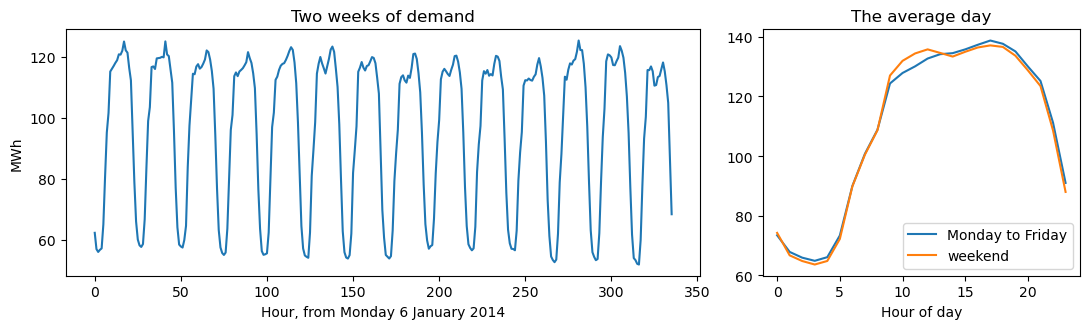

In [2]:
# One row per hour, one column per customer, in kWh. hour_start becomes the row index.
loads = pd.read_csv(DATA / "advanced/electricity_load/electricity_load_hourly.zip",
                    parse_dates=["hour_start"], index_col="hour_start")
print("hours:", len(loads), " customers:", loads.shape[1],
      " first hour:", loads.index[0], " last hour:", loads.index[-1])

# Add up the customers, kWh -> MWh: what the supplier must buy each hour.
demand = loads.sum(axis=1) / 1000
print(f"demand per hour: mean {demand.mean():.1f} MWh")
print(f"lowest hour: {demand.min():.1f} MWh at {demand.idxmin()}; "
      f"highest: {demand.max():.1f} MWh at {demand.idxmax()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(demand["2014-01-06":"2014-01-19"].to_numpy())         # two weeks, Monday to Sunday
axes[0].set_xlabel("Hour, from Monday 6 January 2014")
axes[0].set_ylabel("MWh")
axes[0].set_title("Two weeks of demand")
# The average day: mean demand at each hour of the day, for weekdays and for weekends.
weekend = demand.index.dayofweek >= 5
axes[1].plot(demand[~weekend].groupby(demand.index[~weekend].hour).mean(), label="Monday to Friday")
axes[1].plot(demand[weekend].groupby(demand.index[weekend].hour).mean(), label="weekend")
axes[1].set_xlabel("Hour of day")
axes[1].set_title("The average day")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS / "two_weeks_and_the_average_day.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 3 — Split by date and scale

Rows that are neighbours in time are nearly copies of each other, so the split has to follow the calendar: three years to train, the first half of 2014 to choose settings, and the second half of 2014 as the test period, opened once. The series is then scaled by the highest training hour, so the network sees numbers near $[0, 1]$; the scale is a training statistic, computed before anything looks at 2014.

**Read the code.**

- `pd.Series("train", index=demand.index)` labels every hour `train`. The next two lines overwrite the label from 1 January 2014 and again from 1 July 2014.
- `f"{hours[0]:%d %b %Y}"` prints a date in the form `01 Jan 2011`.
- `scale` is the highest hour of the training period only. Dividing by it puts the training values between 0 and 1, and later values close to that range.
- `.to_numpy(dtype=np.float32)` stores the series as the 32-bit numbers that PyTorch uses by default.

In [3]:
# Label every hour with its period: three years to train, then two half-years.
period = pd.Series("train", index=demand.index)
period[demand.index >= "2014-01-01"] = "validation"
period[demand.index >= "2014-07-01"] = "test"
for name in ["train", "validation", "test"]:
    hours = demand.index[period == name]
    print(f"{name:10s} {len(hours):6d} hours, {hours[0]:%d %b %Y} to {hours[-1]:%d %b %Y}")

# Scale by the highest training hour, so the network sees numbers near [0, 1]. A training statistic only.
scale = float(demand[period == "train"].max())
scaled = (demand / scale).to_numpy(dtype=np.float32)
print(f"scale: {scale:.1f} MWh, the highest training hour")

train       26304 hours, 01 Jan 2011 to 31 Dec 2013
validation   4344 hours, 01 Jan 2014 to 30 Jun 2014
test         4416 hours, 01 Jul 2014 to 31 Dec 2014
scale: 193.6 MWh, the highest training hour


### Question 4 — Build the windows

A *window* turns the series into rows: the 24 values before hour $t$ are the input, and the value at hour $t$ is the label. Sliding one hour at a time gives one row per hour. Each row belongs to the period of the hour it predicts, so the first validation row predicts midnight on 1 January 2014 from the last 24 hours of 2013. That is allowed: those hours are in the past when the forecast is made.

**Read the code.**

- `make_windows` builds one row per hour `t`: `values[t - lookback:t]` is the 24 hours before `t`, and `values[t]` is the label. `np.stack` piles the windows into one array of shape (rows, 24).
- `period.to_numpy()[hours]` looks up the period of each hour being predicted, so a row goes to the period of its label.
- `torch.tensor(...).unsqueeze(-1)` adds a last dimension of size 1. An LSTM expects the shape (rows, steps, values per step), and here each step has one value.
- The last lines multiply by `scale` to print the first window and its label in MWh.

In [4]:
LOOKBACK = 24

def make_windows(values, lookback):
    """Row r holds the `lookback` values before hour t = lookback + r; its label is the value at hour t."""
    hours = np.arange(lookback, len(values))
    windows = np.stack([values[t - lookback:t] for t in hours])
    return windows, values[hours], hours

def split_by_period(X, y, hours):
    """Tensors for the train, validation and test periods.
    A row belongs to the period of the hour it predicts, and each window gets a last dimension
    of size 1: one value per step."""
    of_row = period.to_numpy()[hours]
    splits = []
    for p in ["train", "validation", "test"]:
        X_p = torch.tensor(X[of_row == p]).unsqueeze(-1).to(DEVICE)       # (rows, steps, 1)
        y_p = torch.tensor(y[of_row == p]).to(DEVICE)
        splits.append((X_p, y_p))
    return splits

windows, targets, target_hours = make_windows(scaled, LOOKBACK)
(X_train, y_train), (X_valid, y_valid), (X_test, y_test) = split_by_period(windows, targets, target_hours)
print("windows:", windows.shape, " train:", tuple(X_train.shape), " validation:", tuple(X_valid.shape),
      " test:", tuple(X_test.shape))
print("first window (MWh):", np.round(windows[0, :6] * scale, 1), "...")
print("its label, the next hour:", round(float(targets[0] * scale), 1),
      "MWh at", demand.index[target_hours[0]])

windows: (35040, 24)  train: (26280, 24, 1)  validation: (4344, 24, 1)  test: (4416, 24, 1)
first window (MWh): [68.9 65.6 66.7 65.9 64.8 66.1] ...
its label, the next hour: 68.4 MWh at 2011-01-02 00:00:00


**What the output shows.** 35,064 hours of 158 customers add up to 109.8 MWh in an average hour. The lowest hour, 14.5 MWh at 1 a.m. on 30 March 2014, is not real demand: it is the night the clocks went forward, which the meters record as nearly nothing. The two weeks show one strong daily rhythm, low at night and high in the afternoon, and the average day is almost the same at weekends as on weekdays. Training ends on 31 December 2013; validation is January to June 2014 and the test period July to December 2014. The first window starts at midnight on 1 January 2011, and its label is the next midnight.

**Checkpoint: before you move on**

- 35,064 hours, and 109.8 MWh in an average hour.
- Train on 2011–2013, validate on the first half of 2014, test on the second; the scale is 193.6 MWh.
- 26,280 training windows of 24 hours each.

## Part B — Forecasts that cost nothing

**Goal.** Set the bar that any model has to clear.

*Question 5 · Data: the demand series*

### Question 5 — Compute three free forecasts

Before any network is trained, three forecasts that cost nothing set the bar. *Last hour* says the next hour equals the last one. *Same hour yesterday* repeats the value 24 hours back, the first value in each window. *Same hour last week* repeats the value 168 hours back. A model that cannot beat all three has learned nothing worth its cost.

**Read the code.**

- `demand.shift(1)` moves every value one row down, so each hour is paired with the hour before it. `shift(24)` pairs it with the same hour yesterday, and `shift(168)` with the same hour last week.
- `mae` subtracts a forecast from the demand over the hours of one period and averages the absolute misses. The index lines the two series up hour by hour.
- The dictionary comprehension scores all three forecasts on the validation period.

In [5]:
def mae(forecast, name):
    """Mean absolute error in MWh over the hours of one period."""
    hours = period == name
    return float((demand[hours] - forecast[hours]).abs().mean())

# Each free forecast is the demand series shifted: by 1 hour, by 24 hours, by 168 hours.
free = {"last hour": demand.shift(1), "same hour yesterday": demand.shift(24),
        "same hour last week": demand.shift(168)}
baselines = {name: mae(forecast, "validation") for name, forecast in free.items()}
for name, value in baselines.items():
    print(f"{name:20s} validation MAE = {value:.2f} MWh")

last hour            validation MAE = 5.77 MWh
same hour yesterday  validation MAE = 3.07 MWh
same hour last week  validation MAE = 4.51 MWh


**What the output shows.** Same hour yesterday is the free forecast to beat: an MAE of 3.07 MWh, against 5.77 for the last hour and 4.51 for the same hour last week. With one strong daily rhythm and little difference at weekends, yesterday is a good guess for today.

**Checkpoint: before you move on**

- Validation MAE: last hour 5.77, same hour yesterday 3.07, same hour last week 4.51 MWh.

## Part C — The LSTM

**Goal.** Train an LSTM that keeps its best epoch, open the test period once, and find the hours it gets wrong.

*Questions 6–9 · Data: the 24-hour windows*

### Question 6 — Build and train the LSTM

The model reads the 24 values one at a time, carrying a state of 32 numbers from step to step, and a linear layer turns the final state into one prediction. The training loop is the one from Lab 7 with three changes: the loss is squared error, the score recorded each epoch is the validation MAE in MWh, and the loop keeps a copy of the weights from the best epoch so far. That is *early stopping*: the model you keep is the best epoch, not the last.

**Read the code.**

- `LSTMForecaster` is a class that inherits from `nn.Module`. `__init__` creates the layers, and `forward` says how an input passes through them.
- `nn.LSTM(input_size=1, hidden_size=32, batch_first=True)` reads one value per step and keeps a state of 32 numbers. `batch_first=True` means the input has the shape (rows, steps, values).
- `self.lstm(x)` returns the state after every step. `states[:, -1, :]` keeps the last one, `self.head` turns its 32 numbers into one forecast, and `.squeeze(-1)` drops the leftover dimension of size 1.
- `train_forecaster` is Lab 7's loop with a different loss: `nn.MSELoss()`, the squared error.
- After each epoch it measures the validation MAE. When that is the lowest so far, `copy.deepcopy(model.state_dict())` saves a copy of the weights, and at the end `load_state_dict(best_weights)` puts the best copy back.
- `np.argmin(history) + 1` is the number of the epoch that was kept.

In [6]:
class LSTMForecaster(nn.Module):
    """An LSTM reads the window step by step; a linear layer turns its final state into one forecast."""

    def __init__(self, hidden_size=32, input_size=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        states, _ = self.lstm(x)                          # (rows, steps, hidden): state after each step
        return self.head(states[:, -1, :]).squeeze(-1)    # the final state predicts the next hour

def validation_mae(model, X, y):
    """Mean absolute error in MWh (the model works in scaled units, so multiply back by the scale)."""
    model.eval()
    with torch.no_grad():
        return (model(X) - y).abs().mean().item() * scale

def train_forecaster(model, X, y, X_v, y_v, epochs=12, lr=3e-3, batch_size=64, verbose=True):
    """Train with mean squared error; keep the weights of the epoch with the lowest validation MAE."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history, best_weights = [], None
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X))                    # a new shuffle every epoch
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss_fn(model(X[batch]), y[batch]).backward()
            optimizer.step()
        history.append(validation_mae(model, X_v, y_v))
        if history[-1] == min(history):                   # best epoch so far: keep a copy of its weights
            best_weights = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"epoch {epoch + 1:2d}: validation MAE = {history[-1]:.2f} MWh")
    model.load_state_dict(best_weights)                   # early stopping: the best epoch, not the last
    return history

torch.manual_seed(42)
model = LSTMForecaster().to(DEVICE)
print("trainable weights:", sum(p.numel() for p in model.parameters()))
history = train_forecaster(model, X_train, y_train, X_valid, y_valid)
best_epoch = int(np.argmin(history)) + 1
print(f"kept epoch {best_epoch}: validation MAE = {min(history):.2f} MWh")

trainable weights: 4513


epoch  1: validation MAE = 4.24 MWh


epoch  2: validation MAE = 3.72 MWh


epoch  3: validation MAE = 3.97 MWh


epoch  4: validation MAE = 3.92 MWh


epoch  5: validation MAE = 2.83 MWh


... (3 outputs left out)

epoch  9: validation MAE = 2.56 MWh


epoch 10: validation MAE = 2.16 MWh


epoch 11: validation MAE = 2.21 MWh


epoch 12: validation MAE = 2.29 MWh
kept epoch 10: validation MAE = 2.16 MWh


### Question 7 — Read the validation curve

The validation error per epoch, drawn against the three free forecasts.

**Read the code.**

- `plt.plot` draws the LSTM's validation error per epoch, and one `axhline` per free forecast draws the level it has to get under.
- The dictionary `line_colors` gives each baseline a fixed colour: `C1`, `C2` and `C3` are matplotlib's second, third and fourth default colours.

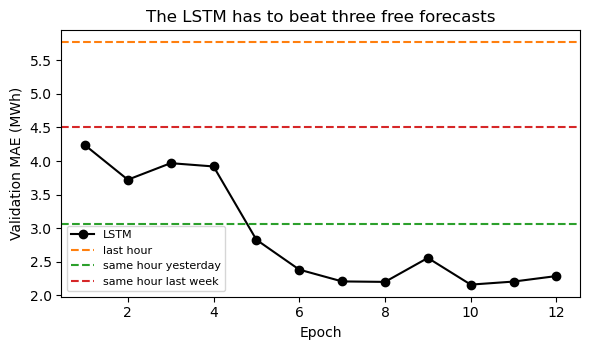

In [7]:
plt.figure(figsize=(6, 3.6))
plt.plot(range(1, len(history) + 1), history, marker="o", color="black", label="LSTM")
line_colors = {"last hour": "C1", "same hour yesterday": "C2", "same hour last week": "C3"}
for name, value in baselines.items():
    plt.axhline(value, linestyle="--", label=name, color=line_colors[name])
plt.xlabel("Epoch")
plt.ylabel("Validation MAE (MWh)")
plt.title("The LSTM has to beat three free forecasts")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "the_lstm_has_to_beat_three_free_forecasts.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 8 — Open the test period once

Now the test half-year, opened once for the free forecasts and for the LSTM.

**Read the code.**

- `model(X_test).cpu().numpy() * scale` turns the forecasts into MWh, and `pd.Series(..., index=demand.index[period == "test"])` attaches the hour to each one.
- `lstm_test.reindex(demand.index)` stretches the series over all the hours, with gaps outside the test period, so the same `mae` function can score it.
- `100 * value / mean_test` expresses each error as a percentage of the average test hour.

In [8]:
# The LSTM's forecasts for every test hour, in MWh, as a series indexed by hour.
model.eval()
with torch.no_grad():
    lstm_test = pd.Series(model(X_test).cpu().numpy() * scale, index=demand.index[period == "test"])

test_scores = {name: mae(forecast, "test") for name, forecast in free.items()}
test_scores["LSTM"] = mae(lstm_test.reindex(demand.index), "test")
mean_test = demand[period == "test"].mean()
for name, value in test_scores.items():
    print(f"{name:20s} test MAE = {value:.2f} MWh ({100 * value / mean_test:.1f}% of the average hour)")

last hour            test MAE = 6.12 MWh (5.7% of the average hour)
same hour yesterday  test MAE = 3.69 MWh (3.4% of the average hour)
same hour last week  test MAE = 4.86 MWh (4.5% of the average hour)
LSTM                 test MAE = 2.57 MWh (2.4% of the average hour)


### Question 9 — Find the hours it gets wrong

A score is one number. The worst hours, the error by hour of day and one test week plotted hour by hour show *where* the forecast goes wrong.

**Read the code.**

- `errors` is the forecast minus the truth for every test hour. `.abs().sort_values(ascending=False).head(6)` lists the six largest misses with their dates.
- `slice("2014-07-07", "2014-07-13")` stores a date range, so the same week can be cut from three series.
- `errors.abs().groupby(errors.index.hour).mean()` is the average miss at each hour of the day.
- `gridspec_kw={"width_ratios": [2, 1]}` makes the left chart twice as wide as the right one.

largest LSTM errors in the test period (MWh):
hour_start
2014-10-26 01:00:00    39.1
2014-10-26 02:00:00    29.2
2014-12-31 19:00:00    25.8
2014-12-25 06:00:00    22.4
2014-12-31 20:00:00    22.1
2014-12-25 07:00:00    21.8


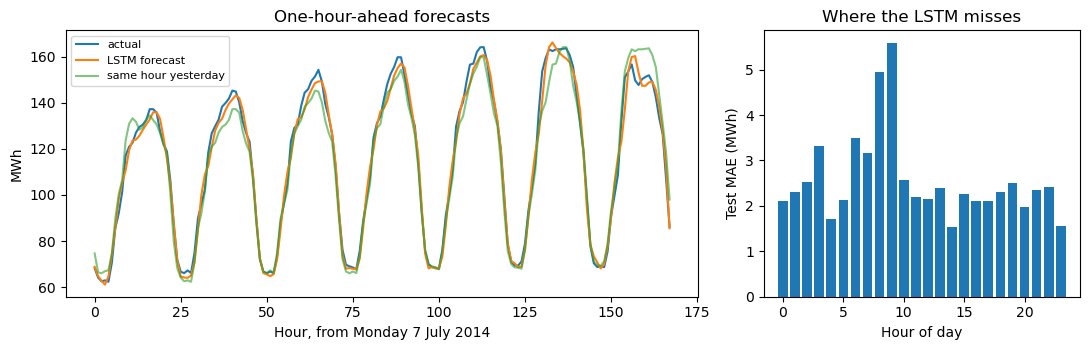

hours of day with the largest MAE: {9: 5.59, 8: 4.94, 6: 3.5}


In [9]:
actual = demand[period == "test"]
errors = (lstm_test - actual).rename("error")
print("largest LSTM errors in the test period (MWh):")
print(errors.abs().sort_values(ascending=False).head(6).round(1).to_string())

week = slice("2014-07-07", "2014-07-13")                     # the first full test week, Monday to Sunday
by_hour = errors.abs().groupby(errors.index.hour).mean()     # the mean miss at each hour of the day

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(actual[week].to_numpy(), label="actual")
axes[0].plot(lstm_test[week].to_numpy(), label="LSTM forecast")
axes[0].plot(free["same hour yesterday"][week].to_numpy(), label="same hour yesterday", alpha=0.6)
axes[0].set_xlabel("Hour, from Monday 7 July 2014")
axes[0].set_ylabel("MWh")
axes[0].set_title("One-hour-ahead forecasts")
axes[0].legend(fontsize=8)
axes[1].bar(by_hour.index, by_hour.to_numpy())
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Test MAE (MWh)")
axes[1].set_title("Where the LSTM misses")
plt.tight_layout()
plt.savefig(RESULTS / "one_hour_ahead_forecasts_and_errors.png", dpi=160, bbox_inches="tight")
plt.show()
print("hours of day with the largest MAE:",
      by_hour.sort_values(ascending=False).head(3).round(2).to_dict())

**What the output shows.** The LSTM has 4,513 weights. Its validation error drops below every free forecast from epoch 5 and reaches its lowest, 2.16 MWh, at epoch 10; epochs 11 and 12 are a little worse, and the loop keeps epoch 10. On the test half-year the LSTM misses by 2.57 MWh in an average hour, 2.4% of demand, against 3.69 for same hour yesterday: 30% less error. The largest misses are not random. The top two are 1 and 2 a.m. on 26 October 2014, the night the clocks went back, when the meters record two hours as one; then New Year's Eve evening and Christmas morning, holidays that break the pattern of the day before, which is what the network leans on. By hour of day, the morning ramp at 8 and 9 a.m. is hardest.

**Checkpoint: before you move on**

- 4,513 weights; the loop keeps epoch 10, at 2.16 MWh.
- Test MAE 2.57 MWh against 3.69 for same hour yesterday.
- The two worst hours are the night the clocks went back, 26 October 2014.

## Part D — Save the weights and the scale with them

**Goal.** Save the weights with the scale they depend on, and make one real forecast.

*Question 10 · Data: the trained LSTM*

### Question 10 — Save the weights and the scale

The network works only on numbers divided by the training maximum, so that number is part of the model. The card records it beside the lookback, the units and the architecture; the restored model is checked against the one in memory and then makes one real forecast: the first hour of 2015.

**Read the code.**

- The weights go into one file and the card into another. The card stores `scale`, without which the saved model's outputs cannot be turned back into MWh.
- `LSTMForecaster()` builds the same empty network, and `load_state_dict` fills in the weights.
- `torch.tensor(scaled[-LOOKBACK:]).reshape(1, LOOKBACK, 1)` shapes the last 24 hours as one window: one row, 24 steps, one value per step.
- `restored(last_day).item() * card["scale"]` is the forecast for the next hour in MWh, and `demand.index[-1] + pd.Timedelta(hours=1)` is the hour it belongs to.

In [10]:
# The weights go to one file; the card records everything needed to use them, the scale above all.
weights_path = MODELS / "electricity_lstm.pt"
torch.save(model.state_dict(), weights_path)
card = {
    "task": ("forecast next-hour total electricity demand (MWh) of 158 Portuguese customers"
             " from the previous 24 hours"),
    "input": (f"tensor of shape (n, {LOOKBACK}, 1): the last {LOOKBACK} hourly totals"
              " in MWh divided by scale"),
    "output": "next-hour demand divided by scale; multiply by scale for MWh",
    "scale": round(scale, 4),
    "architecture": "LSTMForecaster(hidden_size=32) in Lab 8",
    "training": {"period": "2011-01-01 to 2013-12-31", "max_epochs": 12, "kept_epoch": best_epoch,
                 "learning_rate": 3e-3, "batch_size": 64, "seed": 42},
    "validation_mae_mwh": round(min(history), 2),
    "test_mae_mwh": {name: round(value, 2) for name, value in test_scores.items()},
    "torch_version": torch.__version__,
    "trained_on": str(DEVICE),
}
(MODELS / "electricity_lstm_card.json").write_text(json.dumps(card, indent=2))

# Rebuild the network, load the weights, check it forecasts exactly as before, then forecast the next hour.
restored = LSTMForecaster().to(DEVICE)
restored.load_state_dict(torch.load(weights_path, map_location=DEVICE, weights_only=True))
last_day = torch.tensor(scaled[-LOOKBACK:]).reshape(1, LOOKBACK, 1).to(DEVICE)  # the last 24 hours of 2014
restored.eval()
with torch.no_grad():
    same = torch.equal(restored(X_test), model(X_test))
    next_hour = restored(last_day).item() * card["scale"]
print(f"saved {weights_path.name}; reload reproduces the test forecasts: {same}")
print(f"forecast for {demand.index[-1] + pd.Timedelta(hours=1)}: {next_hour:.1f} MWh")

saved electricity_lstm.pt; reload reproduces the test forecasts: True
forecast for 2015-01-01 00:00:00: 53.2 MWh


**What the output shows.** The card holds the scale, 193.6 MWh, and the restored network reproduces every test forecast. Without the scale, `electricity_lstm.pt` would be useless.

**Checkpoint: before you move on**

- The card holds the scale, 193.6 MWh, and the reloaded network reproduces every test forecast.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 11 — Save the evidence

**Read the code.**

- `baselines.get(name, min(history))` returns a baseline's validation error. For the name `LSTM`, which is not in that dictionary, it falls back to the LSTM's own best.
- The third table keeps the actual and the forecast values of the first test week, so the chart of Question 9 can be redrawn.

**Read the code.**

- `baselines.get(name, min(history))` returns a baseline's validation error. For the name `LSTM`, which is not in that dictionary, it falls back to the LSTM's own best.
- The third table keeps the actual and the forecast values of the first test week, so the chart of Question 9 can be redrawn.

In [11]:
pd.DataFrame({"epoch": range(1, len(history) + 1), "validation_mae_mwh": history}).round(3).to_csv(
    RESULTS / "validation_curve.csv", index=False)
metrics = pd.DataFrame([
    {"model": name, "validation_mae_mwh": baselines.get(name, min(history)), "test_mae_mwh": value}
    for name, value in test_scores.items()
])
metrics.round(3).to_csv(RESULTS / "metrics.csv", index=False)
first_week = pd.DataFrame({"actual_mwh": actual[week], "lstm_forecast_mwh": lstm_test[week],
                           "same_hour_yesterday_mwh": free["same hour yesterday"][week]})
first_week.round(2).to_csv(RESULTS / "first_test_week.csv")
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['first_test_week.csv', 'metrics.csv', 'one_hour_ahead_forecasts_and_errors.png', 'the_lstm_has_to_beat_three_free_forecasts.png', 'two_weeks_and_the_average_day.png', 'validation_curve.csv']


## Try it yourself

Train the same LSTM with a lookback of 6 hours and of 48 hours: does the network need a whole day of history, and does it gain from two? Then double `hidden_size` to 64 with the 24-hour lookback, and see whether four times the weights buy a better forecast.

Attempt it in the cell below before reading the solution.

### Question 12 — Try it yourself

In [12]:
# Your work here

### One solution

Two more lookbacks and a wider LSTM, each trained exactly like the one in Question 6.

### Question 13 — One solution

**Read the code.**

- `try_setting` repeats Question 6 for one pair of settings: it builds the windows with the given lookback, seeds PyTorch, trains, and returns the best validation error and the number of weights.
- In `split_by_period(*make_windows(scaled, lookback))`, the `*` passes the three arrays returned by `make_windows` as three arguments. The `_` on the left discards the test tensors, which this comparison must not touch.
- `verbose=False` silences the line printed after every epoch.

**Read the code.**

- `try_setting` repeats Question 6 for one pair of settings: it builds the windows with the given lookback, seeds PyTorch, trains, and returns the best validation error and the number of weights.
- In `split_by_period(*make_windows(scaled, lookback))`, the `*` passes the three arrays returned by `make_windows` as three arguments. The `_` on the left discards the test tensors, which this comparison must not touch.
- `verbose=False` silences the line printed after every epoch.

In [13]:
def try_setting(lookback, hidden_size):
    """Train one LSTM exactly like Question 6; return its best validation MAE and its number of weights."""
    (X_t, y_t), (X_v, y_v), _ = split_by_period(*make_windows(scaled, lookback))
    torch.manual_seed(42)
    candidate = LSTMForecaster(hidden_size=hidden_size).to(DEVICE)
    curve = train_forecaster(candidate, X_t, y_t, X_v, y_v, verbose=False)
    return min(curve), sum(p.numel() for p in candidate.parameters())

for lookback, hidden_size in [(6, 32), (48, 32), (24, 64)]:
    best_mae, n_weights = try_setting(lookback, hidden_size)
    print(f"lookback = {lookback:2d} hours, hidden = {hidden_size}: validation MAE = {best_mae:.2f} MWh, "
          f"{n_weights} weights")
print(f"lookback = 24 hours, hidden = 32: validation MAE = {min(history):.2f} MWh (Question 6)")

lookback =  6 hours, hidden = 32: validation MAE = 3.63 MWh, 4513 weights


lookback = 48 hours, hidden = 32: validation MAE = 2.14 MWh, 4513 weights


lookback = 24 hours, hidden = 64: validation MAE = 2.09 MWh, 17217 weights
lookback = 24 hours, hidden = 32: validation MAE = 2.16 MWh (Question 6)


**What it shows.** Six hours of history is clearly worse, 3.63 MWh: worse even than same hour yesterday, which the network can no longer see. Forty-eight hours gives 2.14, no better than 24 within the epoch-to-epoch wobble, because one day already holds the daily shape. The wider LSTM has 17,217 weights, almost four times as many, and reaches 2.09: a difference smaller than the wobble of one model between epochs. A whole day of history matters; more of everything else does not.